# Sistem Peringatan Dini (EWS) Mahasiswa: Penerapan Kerangka P2I
**Proyek UAS Ilmu Data dalam Pendidikan — Meicky Shoreamanis**

Notebook ini menjalankan Tahap 2–4 dan Gerbang A dari Kerangka *Problem-to-Impact* (P2I):

| Tahap P2I | Bagian notebook |
|---|---|
| 1. Perumusan masalah & keputusan | Bagian 0 (pertanyaan dan waktu keputusan) |
| 2. Pemetaan data | Bagian 1 (memuat 7 tabel OULAD) |
| 3. Pemeriksaan kualitas data | Bagian 2 (data hilang, kebocoran data) |
| 4. Analisis & pemodelan | Bagian 3–4 (fitur minggu 1–6, tiga model) |
| Gerbang A | Bagian 5–6 (akurasi, kapasitas dosen PA, keadilan) |
| 5. Protokol keputusan | Bagian 7 (daftar prioritas untuk chatbot) |

**Dataset:** Open University Learning Analytics Dataset (OULAD), Kuzilek, Hlosta & Zdrahal (2017), *Scientific Data*, 4, 170171. Lisensi CC BY 4.0.

## Bagian 0. Masalah dan keputusan (Tahap 1)
- **Keputusan:** Pada **akhir minggu ke-6** (hari ke-42), dosen PA memilih mahasiswa mana yang dihubungi lebih dulu.
- **Outcome yang ingin dicegah:** mahasiswa **gagal (Fail) atau mengundurkan diri (Withdrawn)** pada akhir mata kuliah.
- **Aturan penting:** model hanya boleh memakai data yang **sudah ada sebelum hari ke-42**. Data sesudahnya tidak boleh dipakai, karena dosen PA belum memilikinya saat mengambil keputusan.
- **Kapasitas layanan:** dosen PA diasumsikan hanya sanggup mendampingi **20% mahasiswa** per mata kuliah.

In [1]:
# Pengaturan dasar. Ubah angka di sini kalau prodi punya aturan lain.
HARI_KEPUTUSAN = 42      # akhir minggu ke-6
KAPASITAS = 0.20         # proporsi mahasiswa yang bisa didampingi dosen PA
ACAK = 42                # angka acak tetap supaya hasil bisa diulang

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score, confusion_matrix
from sklearn.inspection import permutation_importance
pd.set_option('display.width', 140)

## Bagian 1. Memuat data (Tahap 2)
**Cara mendapatkan data (sekali saja):**
1. Unduh OULAD dalam bentuk file zip, misalnya dari https://analyse.kmi.open.ac.uk/open_dataset (`anonymisedData.zip`) atau dari UCI Machine Learning Repository (`open+university+learning+analytics+dataset.zip`). Isi keduanya sama.
2. Di Colab, klik ikon folder di kiri, lalu unggah file zip itu. Nama file zip boleh apa saja.
3. Jalankan sel di bawah. Sel ini mencari file zip yang berisi data OULAD, lalu membukanya ke folder `oulad/`.

In [2]:
import os, zipfile, glob
FOLDER = 'oulad'
if not glob.glob(f'{FOLDER}/**/studentInfo.csv', recursive=True):
    # Cari file zip yang berisi studentInfo.csv (nama file zip boleh apa saja)
    zip_oulad = [f for f in glob.glob('*.zip')
                 if any(n.endswith('studentInfo.csv') for n in zipfile.ZipFile(f).namelist())]
    if not zip_oulad:
        raise FileNotFoundError('File zip OULAD belum diunggah. Lihat petunjuk di atas sel ini.')
    with zipfile.ZipFile(zip_oulad[0]) as z:
        z.extractall(FOLDER)
# Kalau isi zip ternyata ada di dalam subfolder, cari lokasi studentInfo.csv
FOLDER = os.path.dirname(glob.glob(f'{FOLDER}/**/studentInfo.csv', recursive=True)[0])

info  = pd.read_csv(f'{FOLDER}/studentInfo.csv')
reg   = pd.read_csv(f'{FOLDER}/studentRegistration.csv')
asm   = pd.read_csv(f'{FOLDER}/assessments.csv')
s_asm = pd.read_csv(f'{FOLDER}/studentAssessment.csv')
vle   = pd.read_csv(f'{FOLDER}/studentVle.csv')

# Di file asli OULAD, data kosong ditulis dengan tanda '?'. Ubah menjadi kosong (NaN) yang dikenali Python.
for d in [info, reg, asm, s_asm]:
    d.replace('?', np.nan, inplace=True)
asm['date'] = pd.to_numeric(asm['date'], errors='coerce')
s_asm['score'] = pd.to_numeric(s_asm['score'], errors='coerce')

for nama, df in [('studentInfo', info), ('studentRegistration', reg), ('assessments', asm),
                 ('studentAssessment', s_asm), ('studentVle', vle)]:
    print(f'{nama:20s} {df.shape[0]:>10,} baris  {df.shape[1]} kolom')

studentInfo              32,593 baris  12 kolom
studentRegistration      32,593 baris  5 kolom
assessments                 206 baris  6 kolom
studentAssessment       173,912 baris  5 kolom
studentVle           10,655,280 baris  6 kolom


## Bagian 2. Pemeriksaan kualitas data (Tahap 3)

In [3]:
# 2a. Data yang hilang
print('Data hilang per kolom (studentInfo):')
print(info.isna().sum()[info.isna().sum() > 0])
print('\nData hilang (studentRegistration):')
print(reg.isna().sum())
print('\nSebaran hasil akhir:')
print(info['final_result'].value_counts())

Data hilang per kolom (studentInfo):
imd_band    1111
dtype: int64

Data hilang (studentRegistration):
code_module                0
code_presentation          0
id_student                 0
date_registration         45
date_unregistration    22521
dtype: int64

Sebaran hasil akhir:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [4]:
# 2b. Satu baris = satu mahasiswa di satu mata kuliah (modul) pada satu periode
KUNCI = ['code_module', 'code_presentation', 'id_student']
df = info.merge(reg, on=KUNCI, how='left')
print('Duplikat kunci:', df.duplicated(KUNCI).sum())

# 2c. Mencegah kebocoran data (data leakage):
# mahasiswa yang SUDAH mundur sebelum hari ke-42 tidak bisa lagi "dicegah".
# Mereka dikeluarkan karena keputusan dosen PA hanya untuk yang masih aktif.
reg['date_unregistration'] = pd.to_numeric(reg['date_unregistration'], errors='coerce')
df['date_unregistration'] = pd.to_numeric(df['date_unregistration'], errors='coerce')
sudah_mundur = df['date_unregistration'] <= HARI_KEPUTUSAN
print('Mahasiswa yang sudah mundur sebelum hari ke-42 (dikeluarkan):', sudah_mundur.sum())
df = df[~sudah_mundur].copy()

# 2d. Target: 1 = Fail/Withdrawn (perlu didampingi), 0 = Pass/Distinction
df['target'] = df['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
print('Jumlah mahasiswa yang dianalisis:', len(df))
print('Proporsi berisiko (target=1):', round(df['target'].mean(), 3))

Duplikat kunci: 0
Mahasiswa yang sudah mundur sebelum hari ke-42 (dikeluarkan): 5569
Jumlah mahasiswa yang dianalisis: 27024
Proporsi berisiko (target=1): 0.431


## Bagian 3. Membuat fitur dari data minggu 1–6 (Tahap 4)
**Fitur** = petunjuk yang dipakai model. Analoginya seperti dokter yang melihat suhu, tekanan darah, dan denyut nadi sebelum memutuskan.

Semua fitur diambil **hanya dari hari ≤ 42**:
- aktivitas LMS: klik sebelum kuliah dimulai, klik minggu 1–4, klik minggu 5–6, jumlah hari aktif, jumlah materi berbeda yang dibuka;
- tugas: jumlah tugas yang terlewat, yang terlambat, nilai rata-rata, dan tanda "belum ada nilai";
- administrasi: hari pendaftaran, jumlah SKS yang diambil, jumlah percobaan sebelumnya.

**Sengaja tidak dipakai sebagai fitur:** gender, wilayah, usia, indeks kemiskinan (IMD), dan disabilitas. Kolom-kolom ini hanya dipakai untuk **memeriksa keadilan** di Bagian 6.

In [5]:
# 3a. Fitur aktivitas LMS (hanya hari <= 42)
v = vle[vle['date'] <= HARI_KEPUTUSAN].copy()
v['minggu'] = np.where(v['date'] < 0, 0, v['date'] // 7 + 1)   # minggu 0 = sebelum kuliah mulai

f_vle = v.groupby(KUNCI).agg(klik_total=('sum_click', 'sum'),
                            hari_aktif=('date', 'nunique'),
                            materi_dibuka=('id_site', 'nunique')).reset_index()
per_minggu = v.pivot_table(index=KUNCI, columns='minggu', values='sum_click',
                           aggfunc='sum', fill_value=0)
per_minggu.columns = [f'klik_minggu_{int(m)}' for m in per_minggu.columns]
f_vle = f_vle.merge(per_minggu.reset_index(), on=KUNCI, how='left')

# 3b. Fitur tugas: hanya tugas yang tenggatnya <= hari 42
a = asm[(asm['date'] <= HARI_KEPUTUSAN) & (asm['assessment_type'] != 'Exam')]
tugas_jatuh_tempo = a.groupby(['code_module', 'code_presentation']).size().rename('tugas_jatuh_tempo').reset_index()
sa = s_asm.merge(a, on='id_assessment', how='inner')
sa = sa[sa['date_submitted'] <= HARI_KEPUTUSAN]
# Keterlambatan hanya dihitung untuk tugas yang dinilai tutor (TMA). Pada tugas komputer (CMA),
# hampir semua tercatat 'terlambat' (98% di mata kuliah CCC 2014J): ini keanehan pencatatan data.
sa['terlambat'] = ((sa['date_submitted'] > sa['date']) & (sa['assessment_type'] == 'TMA')).astype(int)
sa['score'] = pd.to_numeric(sa['score'], errors='coerce')
f_tugas = sa.groupby(KUNCI).agg(tugas_dikumpulkan=('id_assessment', 'nunique'),
                                tugas_terlambat=('terlambat', 'sum'),
                                nilai_rata2=('score', 'mean')).reset_index()

# 3c. Gabungkan semua
data = (df.merge(f_vle, on=KUNCI, how='left')
          .merge(f_tugas, on=KUNCI, how='left')
          .merge(tugas_jatuh_tempo, on=['code_module', 'code_presentation'], how='left'))
kolom_klik = [c for c in data.columns if c.startswith('klik_') or c in ['hari_aktif', 'materi_dibuka']]
data[kolom_klik] = data[kolom_klik].fillna(0)           # tidak ada baris = tidak ada klik
data[['tugas_dikumpulkan', 'tugas_terlambat']] = data[['tugas_dikumpulkan', 'tugas_terlambat']].fillna(0)
data['tugas_jatuh_tempo'] = data['tugas_jatuh_tempo'].fillna(0)
data['tugas_terlewat'] = (data['tugas_jatuh_tempo'] - data['tugas_dikumpulkan']).clip(lower=0)
# Nilai kosong (belum ada tugas yang dinilai) TIDAK diisi 0, karena 0 berarti "nilai jelek".
# Kita tandai dengan kolom belum_ada_nilai, lalu isi dengan nilai tengah (median).
data['belum_ada_nilai'] = data['nilai_rata2'].isna().astype(int)
data['nilai_rata2'] = data['nilai_rata2'].fillna(data['nilai_rata2'].median())
data['date_registration'] = pd.to_numeric(data['date_registration'], errors='coerce')
data['date_registration'] = data['date_registration'].fillna(data['date_registration'].median())

# Klik digabung menjadi tiga periode (bukan per minggu), karena klik per minggu saling
# berkaitan erat (multikolinearitas) sehingga koefisien regresi logistik sulit dibaca.
for m in range(7):
    if f'klik_minggu_{m}' not in data.columns:
        data[f'klik_minggu_{m}'] = 0
data['klik_pra_kuliah'] = data['klik_minggu_0']
data['klik_minggu_1_4'] = data[['klik_minggu_1', 'klik_minggu_2', 'klik_minggu_3', 'klik_minggu_4']].sum(axis=1)
data['klik_minggu_5_6'] = data['klik_minggu_5'] + data['klik_minggu_6']
# Jumlah klik sangat timpang (ada yang 0, ada yang ribuan). Logaritma membuatnya lebih rata.
for k in ['klik_pra_kuliah', 'klik_minggu_1_4', 'klik_minggu_5_6']:
    data[f'log_{k}'] = np.log1p(data[k])

FITUR = ['log_klik_pra_kuliah', 'log_klik_minggu_1_4', 'log_klik_minggu_5_6', 'hari_aktif',
         'materi_dibuka', 'tugas_terlewat', 'tugas_terlambat', 'nilai_rata2', 'belum_ada_nilai',
         'date_registration', 'studied_credits', 'num_of_prev_attempts']
FITUR = [f for f in FITUR if f in data.columns]
print(len(FITUR), 'fitur:', FITUR)
data[FITUR + ['target']].describe().T.round(2)

12 fitur: ['log_klik_pra_kuliah', 'log_klik_minggu_1_4', 'log_klik_minggu_5_6', 'hari_aktif', 'materi_dibuka', 'tugas_terlewat', 'tugas_terlambat', 'nilai_rata2', 'belum_ada_nilai', 'date_registration', 'studied_credits', 'num_of_prev_attempts']


,count,mean,std,min,25%,50%,75%,max
log_klik_pra_kuliah,27024.0,2.97,1.94,0.0,1.39,3.33,4.50,8.22
log_klik_minggu_1_4,27024.0,4.84,1.62,0.0,4.22,5.19,5.92,8.71
log_klik_minggu_5_6,27024.0,3.50,1.87,0.0,2.48,3.97,4.88,8.31
hari_aktif,27024.0,19.58,13.58,0.0,9.00,17.00,28.00,68.00
materi_dibuka,27024.0,33.51,24.52,0.0,16.00,27.00,47.00,296.00
tugas_terlewat,27024.0,0.15,0.41,0.0,0.00,0.00,0.00,2.00
tugas_terlambat,27024.0,0.08,0.27,0.0,0.00,0.00,0.00,2.00
nilai_rata2,27024.0,74.92,19.04,0.0,69.50,78.00,86.00,100.00
belum_ada_nilai,27024.0,0.16,0.37,0.0,0.00,0.00,0.00,1.00
date_registration,27024.0,-66.18,47.53,-311.0,-95.00,-53.00,-29.00,167.00


## Bagian 4. Membagi data dan melatih tiga model (Tahap 4)
**Cara membagi data:** model dilatih dengan **angkatan 2013** lalu diuji dengan **angkatan 2014**. Ini meniru kenyataan: kampus memakai data tahun lalu untuk membantu angkatan tahun ini.

**Tiga model dibandingkan** (sesuai prinsip P2I: selalu bandingkan dengan yang sederhana):
1. **Aturan sederhana**: tanpa *machine learning*, hanya menghitung tanda bahaya (tugas terlewat, tidak ada klik di minggu 5–6). Ini setara dengan "pengalaman dosen" yang dituliskan.
2. **Regresi logistik**: model sederhana yang mudah dijelaskan.
3. **Random forest**: model yang lebih rumit (gabungan ratusan "pohon keputusan").

In [6]:
latih = data[data['code_presentation'].str.startswith('2013')].copy()
uji   = data[data['code_presentation'].str.startswith('2014')].copy()
X_latih, y_latih = latih[FITUR], latih['target']
X_uji,   y_uji   = uji[FITUR],   uji['target']
print('Data latih (2013):', len(latih), '| Data uji (2014):', len(uji))

# Model 1: aturan sederhana (skor 0-3)
def skor_aturan(d):
    return ((d['tugas_terlewat'] > 0).astype(int)
            + (d['klik_minggu_5_6'] == 0).astype(int)
            + (d['hari_aktif'] < 5).astype(int))

# Model 2: regresi logistik (angka distandarkan dulu agar sebanding)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced'))
logreg.fit(X_latih, y_latih)

# Model 3: random forest
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced',
                            n_jobs=-1, random_state=ACAK)
rf.fit(X_latih, y_latih)

skor = {
    'Aturan sederhana': skor_aturan(uji) + 0.001 * (-uji['hari_aktif'].rank(pct=True)),  # pemecah seri
    'Regresi logistik': logreg.predict_proba(X_uji)[:, 1],
    'Random forest':    rf.predict_proba(X_uji)[:, 1],
}
uji['skor_logreg'] = skor['Regresi logistik']
uji['skor_rf'] = skor['Random forest']

Data latih (2013): 11620 | Data uji (2014): 15404


## Bagian 5. Gerbang A (1): Seberapa baik model? Ukur sesuai kapasitas dosen PA
Dosen PA hanya sanggup menghubungi 20% mahasiswa. Jadi pertanyaannya bukan sekadar "akurat atau tidak", tetapi:
- **Presisi@20%**: dari mahasiswa yang dihubungi, berapa persen yang memang berisiko? (apakah waktu dosen terpakai dengan tepat?)
- **Recall@20%**: dari semua mahasiswa berisiko, berapa persen yang berhasil terjangkau? (berapa yang terlewat?)
- **AUC**: kemampuan model mengurutkan yang berisiko di atas yang tidak berisiko (0,5 = tebakan acak; 1 = sempurna).

Ambang dihitung **per mata kuliah**, karena tiap dosen PA menangani kelasnya sendiri.

In [7]:
def tandai_top(uji, kolom_skor, kapasitas=KAPASITAS):
    """Tandai 20% skor tertinggi di setiap mata kuliah/periode."""
    peringkat = uji.groupby(['code_module', 'code_presentation'])[kolom_skor].rank(ascending=False, pct=True)
    return (peringkat <= kapasitas).astype(int)

hasil = []
for nama, s in skor.items():
    uji['_skor'] = s
    pred = tandai_top(uji, '_skor')
    hasil.append({'Model': nama,
                  'AUC': roc_auc_score(y_uji, s),
                  'Presisi@20%': precision_score(y_uji, pred),
                  'Recall@20%': recall_score(y_uji, pred)})
    uji[f'pred_{nama}'] = pred
tabel_A = pd.DataFrame(hasil).round(3)
print('Proporsi berisiko di data uji:', round(y_uji.mean(), 3))
tabel_A

Proporsi berisiko di data uji: 0.428


,Model,AUC,Presisi@20%,Recall@20%
0,Aturan sederhana,0.702,0.759,0.357
1,Regresi logistik,0.753,0.778,0.363
2,Random forest,0.762,0.798,0.372


In [8]:
# Recall jika kapasitas dosen PA diubah (trade-off kapasitas vs cakupan)
baris = []
for kap in [0.10, 0.20, 0.30, 0.40]:
    pred = tandai_top(uji, 'skor_logreg', kap)
    baris.append({'Kapasitas': f'{int(kap*100)}%', 'Presisi': precision_score(y_uji, pred),
                  'Recall': recall_score(y_uji, pred)})
tabel_kapasitas = pd.DataFrame(baris).round(3)
tabel_kapasitas

,Kapasitas,Presisi,Recall
0,10%,0.851,0.198
1,20%,0.778,0.363
2,30%,0.706,0.494
3,40%,0.651,0.609


## Bagian 6. Gerbang A (2): Apakah model adil antarkelompok?
Kita periksa model regresi logistik pada kelompok **disabilitas**, **gender**, dan **indeks kemiskinan wilayah (IMD)**.
- **Recall per kelompok**: apakah mahasiswa berisiko dari kelompok tertentu lebih sering *terlewat*?
- **Tingkat salah tandai (FPR)**: apakah mahasiswa yang sebenarnya baik-baik saja dari kelompok tertentu lebih sering *dicap berisiko*?

In [9]:
uji['kelompok_disabilitas'] = np.where(uji['disability'].astype(str).isin(['Y', 'True']), 'Disabilitas', 'Non-disabilitas')
uji['kelompok_gender'] = uji['gender'].map({'F': 'Perempuan', 'M': 'Laki-laki'})
imd_angka = uji['imd_band'].astype(str).str.extract(r'^(\d+)')[0].astype(float)
uji['kelompok_imd'] = np.where(imd_angka < 30, 'IMD 0-30% (paling miskin)',
                      np.where(imd_angka.isna(), 'IMD tidak diketahui', 'IMD 30-100%'))

def audit(kol, pred_kol='pred_Regresi logistik'):
    baris = []
    for g, d in uji.groupby(kol):
        tn, fp, fn, tp = confusion_matrix(d['target'], d[pred_kol], labels=[0, 1]).ravel()
        baris.append({'Kelompok': g, 'n': len(d), 'Proporsi berisiko': d['target'].mean(),
                      'Recall': tp / (tp + fn), 'Salah tandai (FPR)': fp / (fp + tn),
                      'Presisi': tp / (tp + fp) if (tp + fp) else np.nan})
    return pd.DataFrame(baris).round(3)

tabel_adil = pd.concat([audit('kelompok_disabilitas'), audit('kelompok_gender'), audit('kelompok_imd')])
tabel_adil

,Kelompok,n,Proporsi berisiko,Recall,Salah tandai (FPR),Presisi
0,Disabilitas,1447,0.527,0.403,0.080,0.848
1,Non-disabilitas,13957,0.417,0.358,0.077,0.769
0,Laki-laki,8827,0.445,0.383,0.061,0.834
1,Perempuan,6577,0.404,0.334,0.098,0.698
0,IMD 0-30% (paling miskin),4676,0.504,0.390,0.088,0.819
1,IMD 30-100%,10125,0.401,0.350,0.075,0.757
2,IMD tidak diketahui,603,0.287,0.306,0.056,0.688


**Cara membaca tabel keadilan.** Bandingkan baris dalam satu kategori. Selisih recall berarti mahasiswa berisiko dari satu kelompok lebih sering *terlewat*. Selisih FPR berarti mahasiswa yang sebenarnya baik-baik saja dari satu kelompok lebih sering *salah ditandai*. Perhatikan juga kolom "Proporsi berisiko": kelompok dengan proporsi berisiko lebih tinggi wajar lebih sering masuk daftar. Pertanyaan etisnya adalah apakah **sebab** risiko itu (misalnya hambatan aksesibilitas materi) ikut ditangani, atau hanya mahasiswanya yang "diperbaiki".

## Bagian 6b. Interpretasi: fitur apa yang paling memengaruhi model?
Untuk regresi logistik, kita lihat **koefisien**: angka positif berarti fitur itu menaikkan skor risiko, angka negatif menurunkannya.
Untuk random forest, kita pakai **permutation importance**: seberapa turun kinerja model kalau satu fitur diacak.

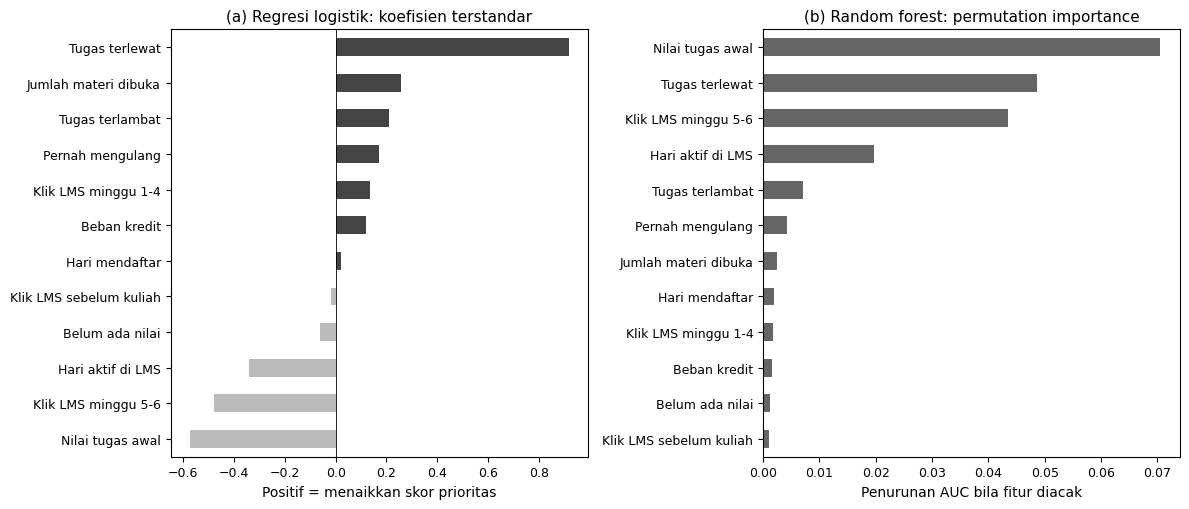

Nilai tugas awal          -0.57
Klik LMS minggu 5-6       -0.48
Hari aktif di LMS         -0.34
Belum ada nilai           -0.06
Klik LMS sebelum kuliah   -0.02
Hari mendaftar             0.02
Beban kredit               0.12
Klik LMS minggu 1-4        0.13
Pernah mengulang           0.17
Tugas terlambat            0.21
Jumlah materi dibuka       0.26
Tugas terlewat             0.92
dtype: float64
Klik LMS sebelum kuliah    0.001
Belum ada nilai            0.001
Beban kredit               0.002
Klik LMS minggu 1-4        0.002
Hari mendaftar             0.002
Jumlah materi dibuka       0.002
Pernah mengulang           0.004
Tugas terlambat            0.007
Hari aktif di LMS          0.020
Klik LMS minggu 5-6        0.044
Tugas terlewat             0.049
Nilai tugas awal           0.070
dtype: float64


In [10]:
koef = pd.Series(logreg[-1].coef_[0], index=FITUR).sort_values()
pi = permutation_importance(rf, X_uji, y_uji, scoring='roc_auc', n_repeats=5, random_state=ACAK, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FITUR).sort_values()

# Nama fitur diterjemahkan supaya gambar bisa langsung dipakai di artikel (Gambar 1)
LABEL = {'log_klik_pra_kuliah': 'Klik LMS sebelum kuliah', 'log_klik_minggu_1_4': 'Klik LMS minggu 1-4',
         'log_klik_minggu_5_6': 'Klik LMS minggu 5-6', 'hari_aktif': 'Hari aktif di LMS',
         'materi_dibuka': 'Jumlah materi dibuka', 'tugas_terlewat': 'Tugas terlewat',
         'tugas_terlambat': 'Tugas terlambat', 'nilai_rata2': 'Nilai tugas awal',
         'belum_ada_nilai': 'Belum ada nilai', 'date_registration': 'Hari mendaftar',
         'studied_credits': 'Beban kredit', 'num_of_prev_attempts': 'Pernah mengulang'}
k = koef.rename(LABEL).sort_values()
im = imp.rename(LABEL).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
k.plot.barh(ax=ax[0], color=['#444444' if v > 0 else '#bbbbbb' for v in k]); ax[0].axvline(0, color='k', lw=.6)
ax[0].set_title('(a) Regresi logistik: koefisien terstandar', fontsize=11)
ax[0].set_xlabel('Positif = menaikkan skor prioritas')
im.plot.barh(ax=ax[1], color='#666666')
ax[1].set_title('(b) Random forest: permutation importance', fontsize=11)
ax[1].set_xlabel('Penurunan AUC bila fitur diacak')
for a in ax:
    a.tick_params(labelsize=9)
plt.tight_layout(); plt.savefig('gambar1.png', dpi=200); plt.show()
print(k.round(2)); print(im.round(3))

**Cara membaca gambar (Gambar 1 artikel).** Kiri: batang gelap menaikkan skor prioritas, batang terang menurunkannya. Kanan: makin panjang batang, makin besar peran fitur itu. Kedua model sepakat bahwa tiga petunjuk terkuat adalah **nilai tugas awal**, **tugas yang terlewat**, dan **aktivitas LMS minggu 5–6**.

Hati-hati: beberapa koefisien (misalnya `materi_dibuka` dan klik minggu 1–4) bertanda positif. Ini bukan berarti "rajin membuka materi itu berbahaya". Fitur-fitur aktivitas saling berkaitan, sehingga koefisien satu fitur hanya bermakna *setelah fitur lain dianggap tetap*. Selain itu, model menunjukkan **asosiasi, bukan sebab**. Karena itu, petunjuk di daftar prioritas hanyalah bahan percakapan dosen PA, bukan diagnosis.

## Bagian 7. Protokol keputusan (Tahap 5): daftar prioritas untuk chatbot dosen PA
Kita buat daftar prioritas untuk **satu mata kuliah** di data uji. Daftar ini dibaca oleh chatbot di VS Code.
- Tidak ada label "berisiko". Yang ada hanya **urutan prioritas dihubungi** dan **petunjuk** (bukan diagnosis).
- ID mahasiswa disamarkan menjadi kode M001, M002, ...
- Kolom disabilitas/gender **tidak** disertakan, supaya dosen PA tidak berprasangka.

In [11]:
MK = uji.groupby(['code_module', 'code_presentation']).size().idxmax()   # mata kuliah terbesar
kelas = uji[(uji['code_module'] == MK[0]) & (uji['code_presentation'] == MK[1])].copy()
kelas = kelas.sort_values('skor_logreg', ascending=False).reset_index(drop=True)
kelas['kode'] = [f'M{i+1:03d}' for i in range(len(kelas))]
kelas['prioritas'] = np.where(kelas.index < int(len(kelas) * KAPASITAS), 'Hubungi minggu ini', 'Pantau')

# Petunjuk per mahasiswa: 3 fitur yang paling menaikkan skornya (kontribusi = koefisien x nilai terstandar)
skala = logreg[0]
z = pd.DataFrame(skala.transform(kelas[FITUR]), columns=FITUR)
kontrib = z * logreg[-1].coef_[0]
# Nama fitur diterjemahkan ke kalimat yang bisa dibaca dosen PA (arah mengikuti tanda koefisien)
koef_lr = pd.Series(logreg[-1].coef_[0], index=FITUR)
TEKS = {'log_klik_pra_kuliah': 'aktivitas LMS sebelum kuliah', 'log_klik_minggu_1_4': 'aktivitas LMS minggu 1-4',
        'log_klik_minggu_5_6': 'aktivitas LMS minggu 5-6', 'hari_aktif': 'jumlah hari aktif di LMS',
        'materi_dibuka': 'jumlah materi yang dibuka', 'tugas_terlewat': 'tugas yang terlewat',
        'tugas_terlambat': 'tugas yang terlambat', 'nilai_rata2': 'nilai tugas awal',
        'belum_ada_nilai': 'belum ada tugas yang dinilai', 'date_registration': 'waktu mendaftar',
        'studied_credits': 'beban SKS', 'num_of_prev_attempts': 'pernah mengulang mata kuliah ini'}
def kalimat(f):
    if f in ['tugas_terlewat', 'tugas_terlambat', 'belum_ada_nilai', 'num_of_prev_attempts']:
        return f'ada {TEKS[f]}' if f != 'belum_ada_nilai' else TEKS[f]
    if f == 'date_registration':
        return 'mendaftar mendekati/sesudah kuliah mulai'
    return f"{TEKS[f]} {'tinggi' if koef_lr[f] > 0 else 'rendah'}"
kelas['petunjuk'] = ['; '.join(kalimat(f) for f in kontrib.iloc[i][kontrib.iloc[i] > 0].sort_values(ascending=False).index[:3])
                     for i in range(len(kelas))]

KOLOM_EKSPOR = ['kode', 'prioritas', 'skor_logreg', 'petunjuk', 'hari_aktif', 'klik_pra_kuliah',
                'klik_minggu_1_4', 'klik_minggu_5_6', 'tugas_jatuh_tempo', 'tugas_dikumpulkan', 'tugas_terlewat', 'tugas_terlambat',
                'nilai_rata2', 'studied_credits', 'num_of_prev_attempts']
ekspor = kelas[KOLOM_EKSPOR].rename(columns={'skor_logreg': 'skor_prioritas'})
ekspor['skor_prioritas'] = ekspor['skor_prioritas'].round(3)
ekspor['nilai_rata2'] = ekspor['nilai_rata2'].round(1)
# Mahasiswa yang belum punya nilai: kosongkan (jangan tampilkan nilai median hasil pengisian)
ekspor.loc[kelas['belum_ada_nilai'].values == 1, 'nilai_rata2'] = np.nan
ekspor.to_csv('daftar_prioritas.csv', index=False)
print('Mata kuliah:', MK, '| jumlah mahasiswa:', len(ekspor),
      '| dihubungi minggu ini:', (ekspor['prioritas'] == 'Hubungi minggu ini').sum())
ekspor.head(10)

Mata kuliah: ('CCC', '2014J') | jumlah mahasiswa: 1926 | dihubungi minggu ini: 385


,kode,prioritas,skor_prioritas,petunjuk,hari_aktif,klik_pra_kuliah,klik_minggu_1_4,klik_minggu_5_6,tugas_jatuh_tempo,tugas_dikumpulkan,tugas_terlewat,tugas_terlambat,nilai_rata2,studied_credits,num_of_prev_attempts
0,M001,Hubungi minggu ini,0.999,nilai tugas awal rendah; ada tugas yang terlew...,6.0,1.0,118.0,0.0,2.0,1.0,1.0,0.0,0.0,60,1
1,M002,Hubungi minggu ini,0.999,nilai tugas awal rendah; ada tugas yang terlew...,1.0,0.0,94.0,0.0,2.0,1.0,1.0,0.0,0.0,120,0
2,M003,Hubungi minggu ini,0.999,ada tugas yang terlewat; aktivitas LMS minggu ...,12.0,65.0,180.0,0.0,2.0,0.0,2.0,0.0,NaN,300,0
3,M004,Hubungi minggu ini,0.999,nilai tugas awal rendah; ada tugas yang terlew...,6.0,0.0,117.0,0.0,2.0,1.0,1.0,0.0,0.0,60,0
4,M005,Hubungi minggu ini,0.999,nilai tugas awal rendah; ada tugas yang terlew...,18.0,27.0,354.0,0.0,2.0,1.0,1.0,0.0,11.0,180,0
5,M006,Hubungi minggu ini,0.999,nilai tugas awal rendah; ada tugas yang terlew...,21.0,67.0,847.0,1.0,2.0,1.0,1.0,0.0,0.0,120,0
6,M007,Hubungi minggu ini,0.999,ada tugas yang terlewat; aktivitas LMS minggu ...,6.0,12.0,47.0,0.0,2.0,0.0,2.0,0.0,NaN,240,0
7,M008,Hubungi minggu ini,0.999,ada tugas yang terlewat; aktivitas LMS minggu ...,3.0,7.0,36.0,0.0,2.0,0.0,2.0,0.0,NaN,60,1
8,M009,Hubungi minggu ini,0.998,ada tugas yang terlewat; aktivitas LMS minggu ...,2.0,0.0,151.0,0.0,2.0,0.0,2.0,0.0,NaN,120,0
9,M010,Hubungi minggu ini,0.998,nilai tugas awal rendah; ada tugas yang terlew...,3.0,0.0,18.0,0.0,2.0,1.0,1.0,0.0,6.0,90,0


## Bagian 8. Ringkasan angka untuk artikel
Sel ini mengumpulkan semua angka yang dikutip di artikel UAS: jumlah sampel (Metode), Tabel 4, Tabel 5, Tabel 6, dan daftar prioritas (Hasil).

In [12]:
print('Jumlah pendaftaran awal         :', len(info))
print('Dikeluarkan (mundur <= hari 42) :', int(sudah_mundur.sum()))
print('Dianalisis                       :', len(data), '| proporsi gagal/mundur:', round(data['target'].mean(), 3))
print('Data latih 2013                  :', len(latih), '| proporsi:', round(y_latih.mean(), 3))
print('Data uji 2014                    :', len(uji), '| proporsi:', round(y_uji.mean(), 3))
print('Batas recall pada kapasitas 20%  :', round(KAPASITAS / y_uji.mean(), 3))
print()
print('TABEL 4. Kinerja tiga model (kapasitas 20%)'); print(tabel_A.to_string(index=False)); print()
print('TABEL 5. Skenario kapasitas (regresi logistik)'); print(tabel_kapasitas.to_string(index=False)); print()
print('TABEL 6. Audit keadilan (regresi logistik, kapasitas 20%)')
print(tabel_adil[tabel_adil['Kelompok'] != 'IMD tidak diketahui'][['Kelompok', 'n', 'Proporsi berisiko', 'Recall', 'Salah tandai (FPR)']].to_string(index=False))
print()
print('Daftar prioritas:', MK, '|', len(ekspor), 'mahasiswa |', int((ekspor['prioritas'] == 'Hubungi minggu ini').sum()), "berstatus 'Hubungi minggu ini'")

Jumlah pendaftaran awal         : 32593
Dikeluarkan (mundur <= hari 42) : 5569
Dianalisis                       : 27024 | proporsi gagal/mundur: 0.431
Data latih 2013                  : 11620 | proporsi: 0.435
Data uji 2014                    : 15404 | proporsi: 0.428
Batas recall pada kapasitas 20%  : 0.468

TABEL 4. Kinerja tiga model (kapasitas 20%)
           Model   AUC  Presisi@20%  Recall@20%
Aturan sederhana 0.702        0.759       0.357
Regresi logistik 0.753        0.778       0.363
   Random forest 0.762        0.798       0.372

TABEL 5. Skenario kapasitas (regresi logistik)
Kapasitas  Presisi  Recall
      10%    0.851   0.198
      20%    0.778   0.363
      30%    0.706   0.494
      40%    0.651   0.609

TABEL 6. Audit keadilan (regresi logistik, kapasitas 20%)
                 Kelompok     n  Proporsi berisiko  Recall  Salah tandai (FPR)
              Disabilitas  1447              0.527   0.403               0.080
          Non-disabilitas 13957              0.417   

## Catatan untuk Gerbang B (belum bisa diuji di sini)
OULAD tidak berisi data intervensi, jadi notebook ini **hanya menjawab Gerbang A** (apakah model layak). Gerbang B (apakah pendampingan dosen PA benar-benar menurunkan angka gagal/mundur) memerlukan uji coba di kampus, misalnya kuasi-eksperimen antarprodi, sesuai Tabel 3 artikel. Unduh `daftar_prioritas.csv` dan `gambar1.png` dari panel folder di kiri.